visualizing policy difference

In [2]:
import numpy as np
import os
import pandas as pd
import pickle
from tqdm import tqdm
project_dir = os.path.expanduser('../')
load_dir_vf = project_dir + "/data/value_functions"
load_dir_π = project_dir + "/data/policies"
from sklearn.utils import resample
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'STIXGeneral'
%config InlineBackend.figure_formats = ['svg']

for fname in sorted(os.listdir(load_dir_π)):
    if fname.endswith(".pkl"):
        var_name = fname.replace(".pkl", "")
        with open(os.path.join(load_dir_π, fname), "rb") as f:
            globals()[var_name] = pickle.load(f)

In [3]:
policies = {"π_minus": π_minus, 
            "π_plus": π_plus,
            "π_mixed": π_mixed,
            "π_minus_gamma_99": π_minus_gamma_99, 
            "π_plus_gamma_99": π_plus_gamma_99,
            "π_mixed_gamma_99": π_mixed_gamma_99,}

for name, π in policies.items():
    π_matrix = np.zeros((750, 25))
    for s, a in π.items():
        if not (0 <= s < 750):
            continue
        if isinstance(a, (int, np.integer)):
            if 0 <= a < 25:
                π_matrix[s, a] = 1.0
        elif isinstance(a, (list, np.ndarray, set)):
            valid_actions = [int(x) for x in a if 0 <= x < 25]
            if valid_actions:
                prob = 1.0 / len(valid_actions)
                for act in valid_actions:
                    π_matrix[s, act] = prob
    policies[name] = π_matrix  # replace dict with np.ndarray

# unpack back to named variables
π_plus            = policies["π_plus"]
π_minus           = policies["π_minus"]
π_mixed           = policies["π_mixed"]
π_plus_gamma_99   = policies["π_plus_gamma_99"]
π_minus_gamma_99  = policies["π_minus_gamma_99"]
π_mixed_gamma_99  = policies["π_mixed_gamma_99"]

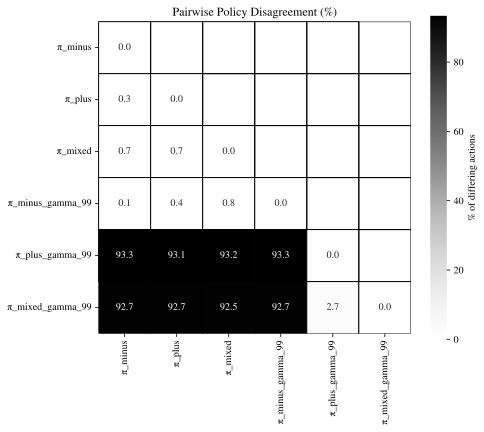

In [13]:
policy_names = list(policies.keys())
nP = len(policy_names)
diff_matrix = np.zeros((nP, nP))


for i, name_i in enumerate(policy_names):
    for j, name_j in enumerate(policy_names):
        π_i = np.asarray(policies[name_i])
        π_j = np.asarray(policies[name_j])
        diff_statewise = np.any(π_i != π_j, axis=1)
        diff_matrix[i, j] = np.mean(diff_statewise)


np.fill_diagonal(diff_matrix, 0)

diff_matrix *= 100
mask = np.triu(np.ones_like(diff_matrix, dtype=bool), k=1)

plt.figure(figsize=(7, 6))
sns.heatmap(
    diff_matrix,
    mask=mask,
    xticklabels=policy_names,
    yticklabels=policy_names,
    cmap="Greys",
    annot=True,
    fmt=".1f",
    linewidths=1,
    linecolor="black",
    cbar_kws={"label": "% of differing actions"},
    square=True
)

plt.title("Pairwise Policy Disagreement (%)")
plt.tight_layout()
plt.show()


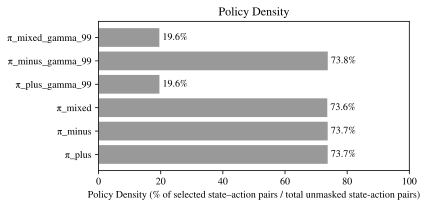

In [17]:
# numbers from 4-check_propositions
densities = {
    "π_plus": 73.73500260824204,
    "π_minus": 73.73500260824204,
    "π_mixed": 73.60459050599896,
    "π_plus_gamma_99": 19.58789775691184,
    "π_minus_gamma_99": 73.76108502869066,
    "π_mixed_gamma_99": 19.561815336463223,
}

fig, ax = plt.subplots(figsize=(6, 3))
names = list(densities.keys())
values = list(densities.values())

bars = ax.barh(names, values, color="gray", alpha=0.8)
ax.set_xlabel("Policy Density (% of selected state–action pairs / total unmasked state-action pairs)")
ax.set_xlim(0, 100)

# Highlight lower-density policies
for bar, val in zip(bars, values):
    ax.text(val + 1, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va="center")

plt.title("Policy Density")
plt.tight_layout()
plt.show()
